# Agricultural Crop Production Prediction Using Machine Learning

**Course:** CSL236 – Introduction to Artificial Intelligence & Machine Learning  
**Project:** Mid-Term Project Evaluation  


### Team Members
1. Maskeen Luthra – 24csu254
2. Bushra Fatima – 24csu265


## Objective
The objective of this project is to preprocess historical agricultural crop
production data and develop a machine learning model for predicting crop
production.

The project focuses on data understanding, missing-value treatment,
categorical encoding, binning, outlier analysis, feature transformation,
scaling, feature selection and model training.

The target variable is **Production**, while agricultural attributes such as
state, district, crop year, season, crop type and cultivated area are used as
predictor variables.

In [2]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
%pip install matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Data Loading and Understanding

The first step is to understand the structure and characteristics of the raw
agricultural dataset. We examine the dataset dimensions, column data types,
summary statistics and missing values before applying any preprocessing.

This is important because preprocessing decisions should be based on the
actual characteristics of the data rather than applying techniques blindly.

In [5]:
df = pd.read_csv("datasets/crop_production.csv")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head(10)

Dataset loaded successfully!
Number of rows: 246091
Number of columns: 7


,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production
0,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Arecanut,1254.0,2000.0
1,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Other Kharif pulses,2.0,1.0
2,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Rice,102.0,321.0
3,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Banana,176.0,641.0
4,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Cashewnut,720.0,165.0
5,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Coconut,18168.0,65100000.0
6,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Dry ginger,36.0,100.0
7,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Sugarcane,1.0,2.0
8,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Sweet potato,5.0,15.0
9,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Tapioca,40.0,169.0


### 1.1 Dataset Structure and Feature Types

The dataset contains **246,091 observations and 7 attributes**. Before preprocessing,
the data types of all attributes are examined and the features are separated into
numerical and categorical variables.

This distinction is necessary because numerical and categorical variables require
different preprocessing techniques such as scaling, imputation and encoding.

In [6]:
print("Dataset Shape:", df.shape)

print("\nColumn Data Types:")
print(df.dtypes)

numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()

print("\nNumerical Columns:")
print(numerical_cols)

print("\nCategorical Columns:")
print(categorical_cols)

Dataset Shape: (246091, 7)

Column Data Types:
State_Name           str
District_Name        str
Crop_Year          int64
Season               str
Crop                 str
Area             float64
Production       float64
dtype: object

Numerical Columns:
['Crop_Year', 'Area', 'Production']

Categorical Columns:
['State_Name', 'District_Name', 'Season', 'Crop']


### 1.2 Summary Statistics

Summary statistics are examined to understand the distribution, central tendency
and spread of the numerical attributes. For categorical attributes, the number of
unique categories and the most frequently occurring values are examined.

In [7]:
print("Numerical Summary Statistics:")
display(df.describe())

print("Categorical Summary Statistics:")
display(df.describe(include="object"))

Numerical Summary Statistics:


,Crop_Year,Area,Production
count,246091.000000,2.460910e+05,2.423610e+05
mean,2005.643018,1.200282e+04,5.825034e+05
std,4.952164,5.052340e+04,1.706581e+07
min,1997.000000,4.000000e-02,0.000000e+00
25%,2002.000000,8.000000e+01,8.800000e+01
50%,2006.000000,5.820000e+02,7.290000e+02
75%,2010.000000,4.392000e+03,7.023000e+03
max,2015.000000,8.580100e+06,1.250800e+09


Categorical Summary Statistics:


C:\Users\maske\AppData\Local\Temp\ipykernel_20416\1546930417.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object"))


,State_Name,District_Name,Season,Crop
count,246091,246091,246091,246091
unique,33,646,6,124
top,Uttar Pradesh,BIJAPUR,Kharif,Rice
freq,33306,945,95951,15104


### 1.3 Missing Value Analysis

Missing values must be identified before model training because incomplete observations
can cause errors or introduce bias. Both the number and percentage of missing values
are calculated for every column so that an appropriate treatment can be selected.

In [8]:
missing_table = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

display(missing_table)

,Missing_Count,Missing_Percentage
State_Name,0,0.00
District_Name,0,0.00
Crop_Year,0,0.00
Season,0,0.00
Crop,0,0.00
Area,0,0.00
Production,3730,1.52


In [9]:
print("Number of duplicate rows:", df.duplicated().sum())

print("\nUnique values in each column:")
display(df.nunique())

print("\nUnique Seasons:")
print(df["Season"].unique())

print("\nNumber of States:", df["State_Name"].nunique())
print("Number of Districts:", df["District_Name"].nunique())
print("Number of Crops:", df["Crop"].nunique())

Number of duplicate rows: 0

Unique values in each column:


State_Name          33
District_Name      646
Crop_Year           19
Season               6
Crop               124
Area             38442
Production       51627
dtype: int64


Unique Seasons:
<ArrowStringArray>
['Kharif     ', 'Whole Year ', 'Autumn     ', 'Rabi       ', 'Summer     ',
 'Winter     ']
Length: 6, dtype: str

Number of States: 33
Number of Districts: 646
Number of Crops: 124


## 2. Data Cleaning and Missing Value Treatment

The missing-value analysis showed that only the **Production** column contains
missing values.

- Missing Production values: **3,730**
- Percentage missing: **1.52%**
- All predictor variables contain 0 missing values.

Since **Production is the target variable**, its missing values are not imputed.
Imputing the target using the mean or median would create artificial production
values and could introduce bias into model training.

Therefore, rows where Production is missing are dropped. Since only 1.52% of the
dataset is affected, this removes a relatively small portion of the observations
while preserving genuine target values.

The categorical text columns are also stripped of leading and trailing whitespace.
For example, values such as "Kharif     " and "Rabi       " contain unnecessary
spaces that could lead to inconsistent category representation during encoding.

In [10]:
# Create a copy before preprocessing
df_clean = df.copy()

# Remove unnecessary whitespace from categorical columns
categorical_text_cols = ["State_Name", "District_Name", "Season", "Crop"]

for col in categorical_text_cols:
    df_clean[col] = df_clean[col].str.strip()

# Drop observations where the TARGET variable is missing
df_clean = df_clean.dropna(subset=["Production"]).copy()

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("Rows removed:", len(df) - len(df_clean))

print("\nMissing values after treatment:")
print(df_clean.isnull().sum())

Original dataset shape: (246091, 7)
Cleaned dataset shape: (242361, 7)
Rows removed: 3730

Missing values after treatment:
State_Name       0
District_Name    0
Crop_Year        0
Season           0
Crop             0
Area             0
Production       0
dtype: int64


In [11]:
print("Seasons after text cleaning:")
print(df_clean["Season"].unique())

Seasons after text cleaning:
<ArrowStringArray>
['Kharif', 'Whole Year', 'Autumn', 'Rabi', 'Summer', 'Winter']
Length: 6, dtype: str


## 3. Outlier Analysis

Agricultural datasets may naturally contain extreme observations because cultivated
area and crop production can differ greatly across crops, districts and states.

Therefore, outliers should not be removed automatically. The IQR method and boxplots
are used to identify extreme values in **Area** and **Production**. The identified
values are then investigated to determine whether they represent data errors or
genuine agricultural observations.

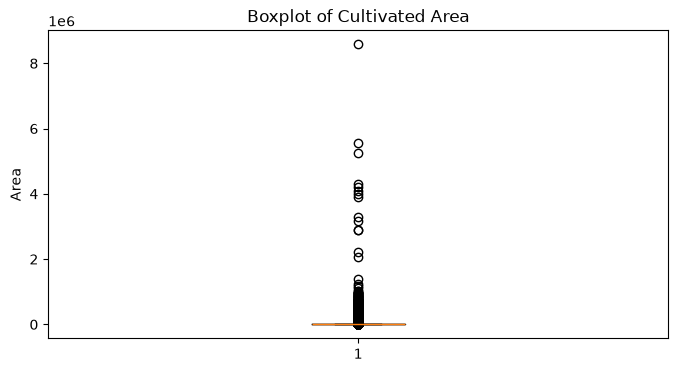

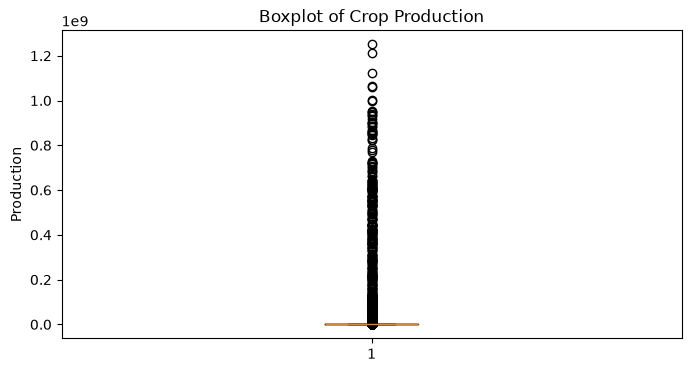

In [12]:
# Boxplots for Area and Production

plt.figure(figsize=(8, 4))
plt.boxplot(df_clean["Area"])
plt.title("Boxplot of Cultivated Area")
plt.ylabel("Area")
plt.show()

plt.figure(figsize=(8, 4))
plt.boxplot(df_clean["Production"])
plt.title("Boxplot of Crop Production")
plt.ylabel("Production")
plt.show()

In [13]:
def detect_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]

    print(f"{column}")
    print(f"Q1: {Q1}")
    print(f"Q3: {Q3}")
    print(f"IQR: {IQR}")
    print(f"Lower Bound: {lower_bound}")
    print(f"Upper Bound: {upper_bound}")
    print(f"Number of potential outliers: {len(outliers)}")
    print(f"Percentage: {len(outliers) / len(data) * 100:.2f}%")
    print("-" * 50)

    return outliers


area_outliers = detect_outliers_iqr(df_clean, "Area")
production_outliers = detect_outliers_iqr(df_clean, "Production")

Area
Q1: 87.0
Q3: 4545.0
IQR: 4458.0
Lower Bound: -6600.0
Upper Bound: 11232.0
Number of potential outliers: 39930
Percentage: 16.48%
--------------------------------------------------
Production
Q1: 88.0
Q3: 7023.0
IQR: 6935.0
Lower Bound: -10314.5
Upper Bound: 17425.5
Number of potential outliers: 42390
Percentage: 17.49%
--------------------------------------------------


In [14]:
print("Largest Production observations:")
display(
    df_clean.nlargest(10, "Production")[
        ["State_Name", "District_Name", "Crop_Year",
         "Season", "Crop", "Area", "Production"]
    ]
)

print("\nLargest Area observations:")
display(
    df_clean.nlargest(10, "Area")[
        ["State_Name", "District_Name", "Crop_Year",
         "Season", "Crop", "Area", "Production"]
    ]
)

Largest Production observations:


,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production
178273,Tamil Nadu,COIMBATORE,2011,Whole Year,Coconut,82704.00,1.250800e+09
178331,Tamil Nadu,COIMBATORE,2013,Whole Year,Coconut,84531.00,1.212000e+09
100654,Kerala,MALAPPURAM,2012,Whole Year,Coconut,102417.00,1.125000e+09
100612,Kerala,MALAPPURAM,2009,Whole Year,Coconut,108380.00,1.063000e+09
100149,Kerala,KOZHIKODE,1999,Whole Year,Coconut,131061.00,1.059000e+09
100391,Kerala,KOZHIKODE,2014,Whole Year,Coconut,123066.00,1.001000e+09
100135,Kerala,KOZHIKODE,1998,Whole Year,Coconut,129506.00,9.990000e+08
100598,Kerala,MALAPPURAM,2008,Whole Year,Coconut,105789.00,9.520000e+08
100373,Kerala,KOZHIKODE,2013,Whole Year,Coconut,123115.00,9.480000e+08
100639,Kerala,MALAPPURAM,2011,Whole Year,Coconut,109229.36,9.467810e+08



Largest Area observations:


,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production
244878,West Bengal,NADIA,1997,Rabi,Oilseeds total,8580100.0,7556300.0
244290,West Bengal,MURSHIDABAD,1997,Rabi,Oilseeds total,5544000.0,4485800.0
243654,West Bengal,MEDINIPUR WEST,1997,Rabi,Oilseeds total,5251200.0,3519600.0
244305,West Bengal,MURSHIDABAD,1997,Whole Year,Pulses total,4307200.0,3632200.0
236486,West Bengal,24 PARAGANAS NORTH,1997,Rabi,Oilseeds total,4205800.0,3183800.0
244891,West Bengal,NADIA,1997,Whole Year,Pulses total,4094900.0,2266000.0
238007,West Bengal,BARDHAMAN,1997,Rabi,Oilseeds total,3989200.0,2899500.0
240719,West Bengal,DINAJPUR UTTAR,1997,Rabi,Oilseeds total,3893900.0,2121300.0
241314,West Bengal,HOOGHLY,1997,Rabi,Oilseeds total,3304700.0,2712500.0
237381,West Bengal,BANKURA,1997,Rabi,Oilseeds total,3179900.0,2118200.0


## 4. Binning / Discretization

The `Area` variable is continuous and highly right-skewed. To demonstrate
discretization and create an interpretable representation of farm/cultivated
area size, equal-frequency (quantile) binning is applied.

Equal-frequency binning was preferred over equal-width binning because Area
contains extreme high values. Equal-width intervals would therefore produce
highly unbalanced groups.

The observations are divided into four categories:

- Small
- Medium
- Large
- Very Large

Each category contains approximately one-quarter of the observations.
The original numerical `Area` feature is retained for prediction because it
contains more precise information. The binned variable is primarily used for
analysis and interpretation.

In [15]:
df_clean["Area_Category"] = pd.qcut(
    df_clean["Area"],
    q=4,
    labels=["Small", "Medium", "Large", "Very Large"],
    duplicates="drop"
)

print("Area categories:")
print(df_clean["Area_Category"].value_counts())

print("\nArea ranges in each category:")
print(
    df_clean.groupby("Area_Category", observed=True)["Area"]
    .agg(["min", "max", "count"])
)

Area categories:
Area_Category
Small         60764
Very Large    60587
Large         60557
Medium        60453
Name: count, dtype: int64

Area ranges in each category:
                   min        max  count
Area_Category                           
Small             0.10       87.0  60764
Medium           87.46      603.0  60453
Large           604.00     4545.0  60557
Very Large     4546.00  8580100.0  60587


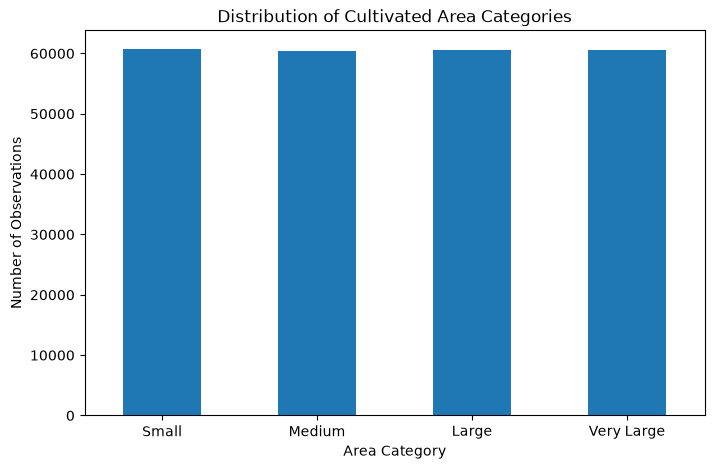

In [16]:
area_counts = df_clean["Area_Category"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
area_counts.plot(kind="bar")
plt.title("Distribution of Cultivated Area Categories")
plt.xlabel("Area Category")
plt.ylabel("Number of Observations")
plt.xticks(rotation=0)
plt.show()

## 5. Feature-Target Separation and Train/Test Split

The target variable for this project is **Production**, making this a
supervised regression problem.

The predictor variables are:

- State_Name
- District_Name
- Crop_Year
- Season
- Crop
- Area

`Area_Category` is not included as an additional model feature because it is
derived directly from Area and would duplicate information already represented
by the original continuous feature.

The data is split into training and testing sets before fitting any encoder or
scaler. This prevents data leakage because preprocessing parameters must be
learned only from the training data.

In [17]:
features = [
    "State_Name",
    "District_Name",
    "Crop_Year",
    "Season",
    "Crop",
    "Area"
]

X = df_clean[features].copy()
y = df_clean["Production"].copy()

print("Input features:", X.columns.tolist())
print("Number of input features:", X.shape[1])
print("Target variable: Production")

Input features: ['State_Name', 'District_Name', 'Crop_Year', 'Season', 'Crop', 'Area']
Number of input features: 6
Target variable: Production


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

Training set: (193888, 6)
Testing set: (48473, 6)

Training target: (193888,)
Testing target: (48473,)


## 6. Categorical Encoding

The categorical predictors `State_Name`, `District_Name`, `Season`, and `Crop`
are **nominal variables** because their categories do not have a meaningful
numerical order.

For example, one crop cannot meaningfully be considered "greater than" another
crop, and one state is not numerically ranked above another state.

Therefore, ordinal encoding is not appropriate.

One-hot encoding is used for these nominal variables. It creates binary
indicator columns without introducing an artificial ranking between categories.

There are no genuine binary or ordinal categorical predictor variables in this
dataset. Therefore, binary mapping and ordinal encoding are not applied.
Applying them artificially would misrepresent the data.

In [19]:
categorical_features = [
    "State_Name",
    "District_Name",
    "Season",
    "Crop"
]

numerical_features = [
    "Crop_Year",
    "Area"
]

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Categorical features: ['State_Name', 'District_Name', 'Season', 'Crop']
Numerical features: ['Crop_Year', 'Area']


## 7. Feature Scaling

The numerical predictors `Crop_Year` and `Area` are measured on very different
scales. StandardScaler is therefore included in the preprocessing pipeline.

The scaler is fitted only on the training data to prevent information from the
test set from influencing preprocessing.

Although tree-based models such as Random Forest are relatively insensitive to
feature scaling, scaling is demonstrated as part of the preprocessing pipeline
and makes the processed features suitable for algorithms that are sensitive to
feature magnitude.

In [20]:
categorical_transformer = Pipeline(
    steps=[
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            )
        )
    ]
)

numerical_transformer = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", categorical_transformer, categorical_features),
        ("numerical", numerical_transformer, numerical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


## 8. Transformation of the Target Variable

The Production variable is highly right-skewed. Its mean is approximately
582,503 while its median is only 729, indicating that a relatively small number
of very large production observations strongly affect the distribution.

These extreme values are not automatically removed because they may represent
genuine agricultural observations.

Instead, a log transformation is applied to the target:

    log(1 + Production)

`log1p` is used instead of the ordinary logarithm because the dataset contains
zero-production observations. The transformation reduces skewness while
retaining the observations.

Predictions are later converted back to the original production scale using
`expm1` so that evaluation metrics remain interpretable.

In [21]:
print("Production skewness before transformation:")
print(y_train.skew())

y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

print("\nProduction skewness after log1p transformation:")
print(y_train_log.skew())

Production skewness before transformation:
41.498613763038705

Production skewness after log1p transformation:
0.17234334321533173


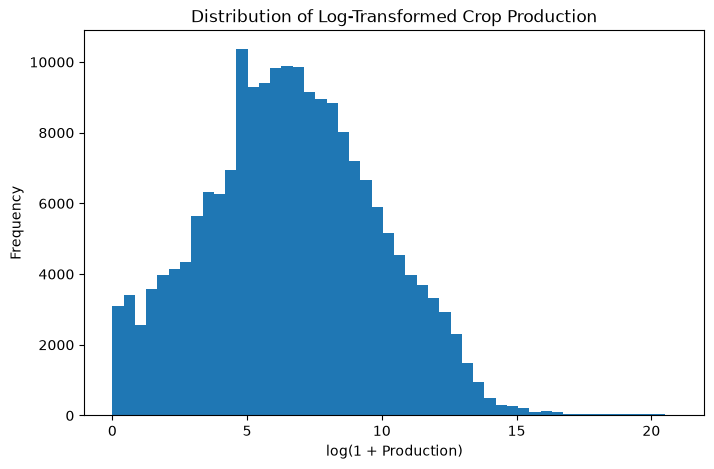

In [22]:
plt.figure(figsize=(8, 5))
plt.hist(y_train_log, bins=50)
plt.title("Distribution of Log-Transformed Crop Production")
plt.xlabel("log(1 + Production)")
plt.ylabel("Frequency")
plt.show()

In [23]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

print("Original number of predictor features:", X_train.shape[1])
print("Features after preprocessing/encoding:", len(feature_names))

print("\nProcessed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Original number of predictor features: 6
Features after preprocessing/encoding: 811

Processed training shape: (193888, 811)
Processed testing shape: (48473, 811)


In [24]:
from sklearn.feature_selection import SelectKBest, f_regression

## 9. Dimensionality Reduction through Feature Selection

The original dataset contains only six predictor variables. However, one-hot
encoding substantially increases the dimensionality because categorical
variables such as District and Crop contain many unique categories.

Feature selection is therefore applied after encoding.

`SelectKBest` with the `f_regression` scoring function is used to retain the
features having the strongest statistical relationship with the continuous
target variable.

Feature selection was preferred over PCA because the selected encoded features
remain interpretable, whereas PCA would transform them into abstract principal
components.

The selector is fitted using the training data only to avoid data leakage.

In [25]:
k = min(100, X_train_processed.shape[1])

selector = SelectKBest(
    score_func=f_regression,
    k=k
)

X_train_selected = selector.fit_transform(
    X_train_processed,
    y_train_log
)

X_test_selected = selector.transform(
    X_test_processed
)

selected_mask = selector.get_support()
selected_features = feature_names[selected_mask]

print("Features before selection:", X_train_processed.shape[1])
print("Features after selection:", X_train_selected.shape[1])

print("\nFirst 20 selected features:")
for feature in selected_features[:20]:
    print(feature)

Features before selection: 811
Features after selection: 100

First 20 selected features:
categorical__State_Name_Andhra Pradesh
categorical__State_Name_Chhattisgarh
categorical__State_Name_Gujarat
categorical__State_Name_Haryana
categorical__State_Name_Himachal Pradesh
categorical__State_Name_Jammu and Kashmir
categorical__State_Name_Kerala
categorical__State_Name_Madhya Pradesh
categorical__State_Name_Maharashtra
categorical__State_Name_Mizoram
categorical__State_Name_Odisha
categorical__State_Name_Puducherry
categorical__State_Name_Punjab
categorical__State_Name_Rajasthan
categorical__State_Name_Telangana
categorical__State_Name_Tripura
categorical__State_Name_Uttarakhand
categorical__District_Name_BANAS KANTHA
categorical__District_Name_BILASPUR
categorical__District_Name_BOUDH


## 10. Model Training

This is a regression problem because the target variable, Production, is
continuous.

A Random Forest Regressor is used as the baseline machine-learning model.
Random Forest can capture nonlinear relationships and interactions between
agricultural variables and is suitable for tabular data.

The model is trained using only the preprocessed and selected training features.
The target is trained on the log-transformed production values.

In [26]:
model = RandomForestRegressor(
    n_estimators=50,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train_selected, y_train_log)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [27]:
# Predict log-transformed production
y_pred_log = model.predict(X_test_selected)

# Convert predictions back to original Production scale
y_pred = np.expm1(y_pred_log)

print("Predictions generated successfully!")

Predictions generated successfully!


## 11. Model Evaluation

The model is evaluated on the unseen test dataset.

Three regression metrics are reported:

- **MAE (Mean Absolute Error):** average absolute difference between actual
  and predicted production.
- **RMSE (Root Mean Squared Error):** penalizes larger prediction errors more
  heavily.
- **R² Score:** indicates the proportion of variation in Production explained
  by the model.

The purpose of this mid-term evaluation is primarily to demonstrate a correct
preprocessing pipeline rather than maximize predictive performance.

In [28]:
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("MODEL PERFORMANCE")
print("-" * 40)
print(f"MAE  : {mae:,.2f}")
print(f"RMSE : {rmse:,.2f}")
print(f"R²   : {r2:.4f}")

MODEL PERFORMANCE
----------------------------------------
MAE  : 319,029.89
RMSE : 11,966,832.50
R²   : 0.6441


In [29]:
comparison = pd.DataFrame({
    "Actual Production": y_test.values,
    "Predicted Production": y_pred
})

display(comparison.head(10))

,Actual Production,Predicted Production
0,4529.0,4131.851421
1,425.0,699.950825
2,254.0,90.602756
3,7.0,9.218037
4,130.0,97.502649
5,21.0,47.992435
6,98392.0,131423.710186
7,182.0,546.831733
8,835.0,60.121315
9,190.0,249.474618


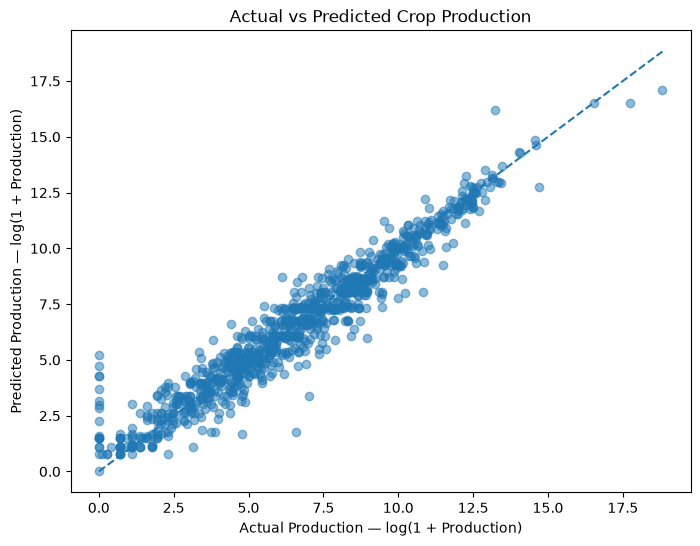

In [30]:
sample = comparison.sample(
    n=min(1000, len(comparison)),
    random_state=42
)

plt.figure(figsize=(8, 6))

plt.scatter(
    np.log1p(sample["Actual Production"]),
    np.log1p(sample["Predicted Production"]),
    alpha=0.5
)

min_val = min(
    np.log1p(sample["Actual Production"]).min(),
    np.log1p(sample["Predicted Production"]).min()
)

max_val = max(
    np.log1p(sample["Actual Production"]).max(),
    np.log1p(sample["Predicted Production"]).max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.title("Actual vs Predicted Crop Production")
plt.xlabel("Actual Production — log(1 + Production)")
plt.ylabel("Predicted Production — log(1 + Production)")
plt.show()

## 12. Conclusion

This project demonstrated an end-to-end machine learning preprocessing pipeline
for agricultural crop production prediction.

The original dataset contained **246,091 rows and 7 columns**. Missing-value
analysis showed that only the target variable, Production, contained missing
values, with **3,730 missing observations (1.52%)**. These rows were removed
rather than imputing artificial target values.

Categorical text values were cleaned to remove unnecessary whitespace.
State, District, Season and Crop were identified as nominal categorical
variables and encoded appropriately using one-hot encoding.

The continuous Area variable was discretized using equal-frequency binning for
interpretability. Potential outliers in Area and Production were investigated
rather than automatically removed because extreme agricultural observations can
represent genuine differences between crops and regions.

Production was highly right-skewed, so a log1p transformation was used. Numerical
features were standardized and the high-dimensional feature space produced by
one-hot encoding was reduced using SelectKBest feature selection.

The dataset was split into training and testing sets before fitting the encoder,
scaler or feature selector in order to prevent data leakage.

Finally, a Random Forest Regressor was trained on the preprocessed data. The
model achieved an **MAE of 319,029.89**, **RMSE of 11,966,832.50**, and
**R² score of 0.6441** on the test set.

The project demonstrates that careful preprocessing, appropriate treatment of
different data types and prevention of data leakage are essential parts of
building a reliable machine learning workflow.

## References and Tools Used

- **Python Documentation / Library Documentation** — referenced for Python and
  machine-learning library usage.
- **Pandas** — data loading, cleaning and exploratory analysis.
- **Scikit-learn** — preprocessing, feature selection, train/test splitting,
  Random Forest regression and evaluation metrics.
- **Matplotlib** — data visualization.


Comparative Analysis of Classification Algorithms

## Objective
To compare Logistic Regression, KNN, Decision Tree,
Naive Bayes, Random Forest and XGBoost using
5-Fold Cross-Validation.

In [34]:
%pip install xgboost scikit-learn pandas numpy matplotlib seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ----------------------


[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    OrdinalEncoder,
    LabelEncoder
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from xgboost import XGBClassifier

print("All libraries imported successfully!")

All libraries imported successfully!


2. Load the dataset

In [36]:
df = pd.read_csv("datasets/crop_production.csv")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (246091, 7)


,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production
0,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Arecanut,1254.0,2000.0
1,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Other Kharif pulses,2.0,1.0
2,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Rice,102.0,321.0
3,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Banana,176.0,641.0
4,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Cashewnut,720.0,165.0


3. Data preparation
We will remove missing target values and create three production categories using quantiles.

In [37]:
# Remove rows with missing production
df = df.dropna(subset=["Production"]).copy()

# Remove unnecessary spaces
categorical_cols = [
    "State_Name",
    "District_Name",
    "Season",
    "Crop"
]

for col in categorical_cols:
    df[col] = df[col].astype(str).str.strip()

# Convert Production into three categories
df["Production_Category"] = pd.qcut(
    df["Production"],
    q=3,
    labels=["Low", "Medium", "High"]
)

print("Production Category Distribution:")
print(df["Production_Category"].value_counts())

print("\nDataset Shape:", df.shape)

Production Category Distribution:
Production_Category
Medium    80790
Low       80788
High      80783
Name: count, dtype: int64

Dataset Shape: (242361, 8)


4. Select features and target
We will use the following input features:
- State_Name
- District_Name
- Crop_Year
- Season
- Crop
- Area
Target: Production_Category

In [38]:
X = df[
    [
        "State_Name",
        "District_Name",
        "Crop_Year",
        "Season",
        "Crop",
        "Area"
    ]
]

y = df["Production_Category"]

# Encode target labels
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

print("Target Classes:", label_encoder.classes_)

# Stratified sample to make KNN and cross-validation practical
sample_size = min(30000, len(X))

sample_indices = (
    pd.Series(y)
    .groupby(y)
    .sample(
        n=None,
        frac=None
    )
    if False else None
)

# Reproducible stratified sampling
X_sample, _, y_sample, _ = train_test_split(
    X,
    y,
    train_size=sample_size,
    random_state=42,
    stratify=y
)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X_sample,
    y_sample,
    test_size=0.2,
    random_state=42,
    stratify=y_sample
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Target Classes: ['High' 'Low' 'Medium']
Training data: (24000, 6)
Testing data: (6000, 6)


6. Define the six classification models

In [39]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=20,
        random_state=42
    ),

    "Naive Bayes": GaussianNB(),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        random_state=42,
        eval_metric="mlogloss",
        n_jobs=-1
    )
}

print("Six classification models created successfully!")

Six classification models created successfully!


In [47]:
# Numerical features
numerical_features = ["Crop_Year", "Area"]

# Categorical features
categorical_features = [
    "State_Name",
    "District_Name",
    "Season",
    "Crop"
]

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# General preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing defined successfully!")

Preprocessing defined successfully!


In [48]:
nb_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),

        ("cat", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1
            ))
        ]), categorical_features)
    ],
    sparse_threshold=0
)

print("Naive Bayes preprocessing ready!")

Naive Bayes preprocessing ready!


7. Apply 5-Fold Cross-Validation
Cross-validation divides training data into five parts. Each part gets an opportunity to act as validation data.

In [50]:
# 5-Fold Stratified Cross Validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "precision": "precision_macro",
    "recall": "recall_macro",
    "f1": "f1_macro"
}

cv_results = []

# Evaluate all six models
for name, model in models.items():

    print(f"\n{'='*50}")
    print(f"Evaluating: {name}")
    print('='*50)

    # Select appropriate preprocessing
    if name == "Naive Bayes":
        current_preprocessor = nb_preprocessor
    else:
        current_preprocessor = preprocessor

    # Create pipeline
    pipeline = Pipeline(steps=[
        ("preprocessor", current_preprocessor),
        ("classifier", model)
    ])

    try:
        # Perform 5-fold cross-validation
        scores = cross_validate(
            pipeline,
            X_train,
            y_train,
            cv=cv,
            scoring=scoring,
            n_jobs=1,
            error_score="raise"
        )

        # Store results
        cv_results.append({
            "Model": name,
            "CV Accuracy": scores["test_accuracy"].mean(),
            "CV Precision": scores["test_precision"].mean(),
            "CV Recall": scores["test_recall"].mean(),
            "CV F1 Score": scores["test_f1"].mean()
        })

        print("Status: SUCCESS")
        print("Average CV Accuracy:",
              round(scores["test_accuracy"].mean(), 4))

        print("Average CV Precision:",
              round(scores["test_precision"].mean(), 4))

        print("Average CV Recall:",
              round(scores["test_recall"].mean(), 4))

        print("Average CV F1 Score:",
              round(scores["test_f1"].mean(), 4))

    except Exception as e:

        print("Status: FAILED")
        print("Error:", repr(e))


# Convert results into DataFrame
results_df = pd.DataFrame(cv_results)

# Display final comparison
print("\n\nFINAL CROSS VALIDATION RESULTS")
print("="*50)

if not results_df.empty:

    results_df = results_df.sort_values(
        by="CV Accuracy",
        ascending=False
    )

    display(results_df)

else:
    print("No models completed successfully.")


Evaluating: Logistic Regression
Status: SUCCESS
Average CV Accuracy: 0.7661
Average CV Precision: 0.7691
Average CV Recall: 0.7661
Average CV F1 Score: 0.7666

Evaluating: KNN
Status: SUCCESS
Average CV Accuracy: 0.7041
Average CV Precision: 0.7013
Average CV Recall: 0.7041
Average CV F1 Score: 0.702

Evaluating: Decision Tree
Status: SUCCESS
Average CV Accuracy: 0.8835
Average CV Precision: 0.8845
Average CV Recall: 0.8835
Average CV F1 Score: 0.8838

Evaluating: Naive Bayes
Status: SUCCESS
Average CV Accuracy: 0.5818
Average CV Precision: 0.6439
Average CV Recall: 0.5818
Average CV F1 Score: 0.5557

Evaluating: Random Forest
Status: SUCCESS
Average CV Accuracy: 0.8567
Average CV Precision: 0.8561
Average CV Recall: 0.8567
Average CV F1 Score: 0.8551

Evaluating: XGBoost
Status: SUCCESS
Average CV Accuracy: 0.8883
Average CV Precision: 0.8886
Average CV Recall: 0.8883
Average CV F1 Score: 0.8884


FINAL CROSS VALIDATION RESULTS


,Model,CV Accuracy,CV Precision,CV Recall,CV F1 Score
5,XGBoost,0.888292,0.888603,0.888292,0.888423
2,Decision Tree,0.883458,0.884488,0.883458,0.883775
4,Random Forest,0.856667,0.856064,0.856667,0.855064
0,Logistic Regression,0.766083,0.769059,0.766083,0.766598
1,KNN,0.704083,0.701320,0.704083,0.701951
3,Naive Bayes,0.581792,0.643950,0.581792,0.555651


8. Train and evaluate models on testing data
After cross-validation, we evaluate each model on the separate testing dataset.

In [51]:
test_results = []
trained_models = {}

for name, model in models.items():

    print(f"\nTraining: {name}")

    current_preprocessor = (
        nb_preprocessor if name == "Naive Bayes"
        else preprocessor
    )

    pipeline = Pipeline(steps=[
        ("preprocessor", current_preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    trained_models[name] = pipeline

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    })

test_results_df = pd.DataFrame(test_results)

display(
    test_results_df.sort_values(
        by="Accuracy",
        ascending=False
    )
)


Training: Logistic Regression

Training: KNN

Training: Decision Tree

Training: Naive Bayes

Training: Random Forest

Training: XGBoost


,Model,Accuracy,Precision,Recall,F1 Score
2,Decision Tree,0.888667,0.891181,0.888667,0.889452
5,XGBoost,0.885000,0.886009,0.885000,0.885393
4,Random Forest,0.859000,0.858683,0.859000,0.858337
0,Logistic Regression,0.767167,0.769976,0.767167,0.767714
1,KNN,0.726833,0.724057,0.726833,0.724766
3,Naive Bayes,0.577333,0.643487,0.577333,0.550560


9. Visualize model comparison

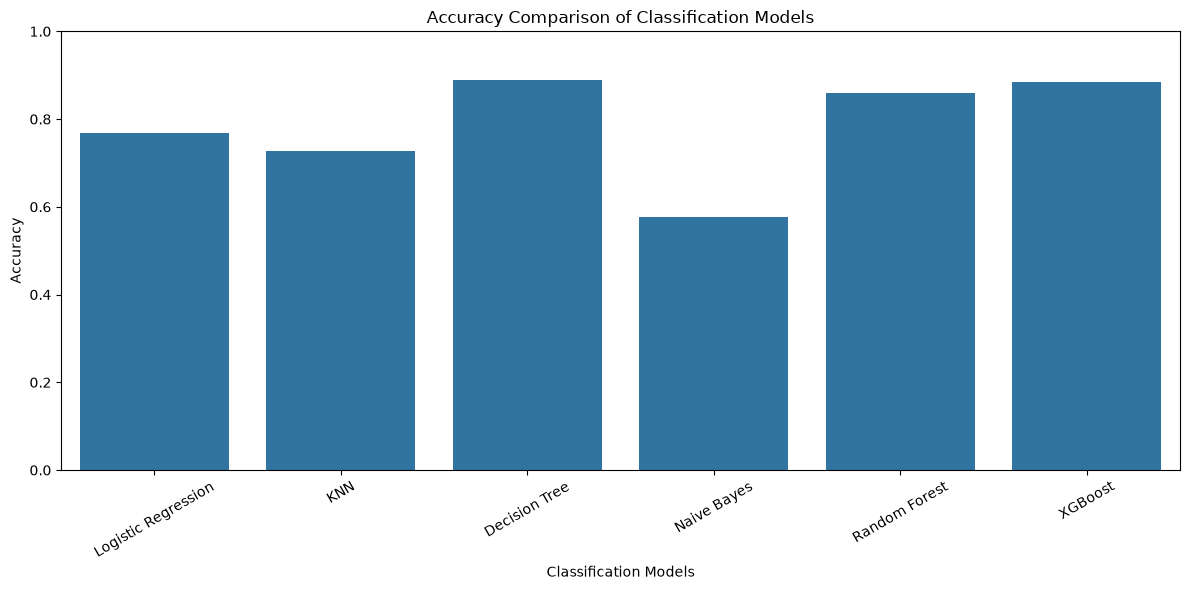

In [52]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=test_results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Accuracy Comparison of Classification Models")
plt.xlabel("Classification Models")
plt.ylabel("Accuracy")
plt.xticks(rotation=30)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

10. Compare all evaluation metrics

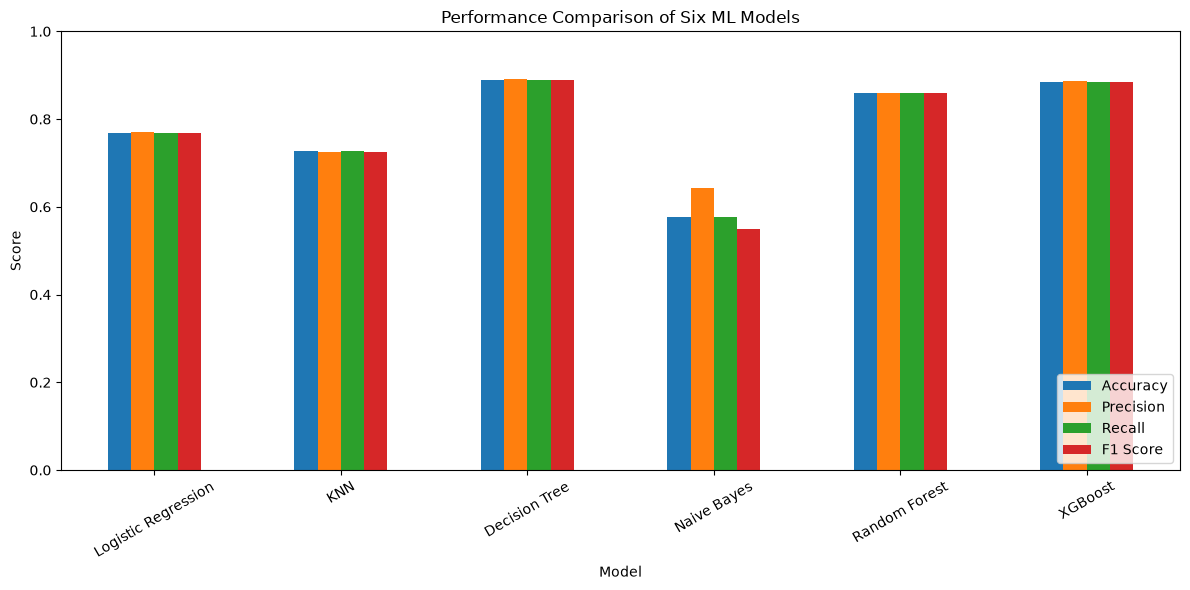

In [53]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

test_results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Performance Comparison of Six ML Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

11. Find the best-performing model

In [54]:
best_model = test_results_df.loc[
    test_results_df["Accuracy"].idxmax()
]

print("BEST PERFORMING MODEL")
print("---------------------")

print("Model:", best_model["Model"])
print("Accuracy:", round(best_model["Accuracy"], 4))
print("Precision:", round(best_model["Precision"], 4))
print("Recall:", round(best_model["Recall"], 4))
print("F1 Score:", round(best_model["F1 Score"], 4))

BEST PERFORMING MODEL
---------------------
Model: Decision Tree
Accuracy: 0.8887
Precision: 0.8912
Recall: 0.8887
F1 Score: 0.8895


12. Confusion matrix of the best model


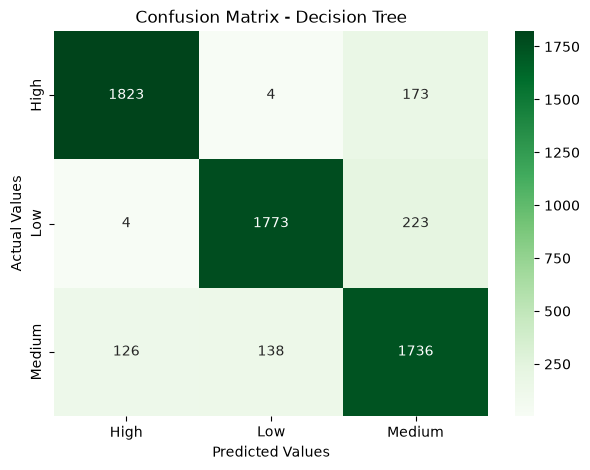

              precision    recall  f1-score   support

        High       0.93      0.91      0.92      2000
         Low       0.93      0.89      0.91      2000
      Medium       0.81      0.87      0.84      2000

    accuracy                           0.89      6000
   macro avg       0.89      0.89      0.89      6000
weighted avg       0.89      0.89      0.89      6000



In [55]:
best_model_name = best_model["Model"]

best_pipeline = trained_models[best_model_name]

y_pred = best_pipeline.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

print(classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_
))